# GPA778 - Laboratory 1.3
# Part C - Localization I: Encoder Odometry

For this final part of Laboratory #1, we will now use the functionalities developed previously to take a first step toward robot localization algorithms. More specifically, the goal is to apply the theoretical knowledge acquired during the course to develop the kinematic model of the robot used in the laboratory, which has a differential-drive robot configuration. The main objective is to enable you to automatically localize the robot $(x, y, \theta)$ in an inertial reference frame.

## 1.3.1 Academic Objectives

The objective of this laboratory is first to review the kinematic equations of a differential-drive robot. Once these equations are well understood and the robot's functional parameters have been identified, the equations will be implemented in a ROS node that will subsequently allow us to localize the robot in an inertial reference frame. More specifically, the objectives for this laboratory session are:

- Develop the robot's kinematic equations in discrete form and implement them in a ROS node in Python
- Deepen the concepts of object-oriented programming methods in Python and understand how to embed subscribers within a class
- Program methods in a Python class. Some of these methods will act as callbacks when messages are received
- Become familiar with using messages more complex than the `std_msgs` (e.g., String or Int32) seen previously, such as `geometry_msgs`, and more specifically the `TransformStamped` message type
- Learn how to use a broadcaster and use it to visualize reference frames in the Rviz2 utility
- Evaluate the developed kinematic model through simple open-loop navigation experiments in order to observe both the effectiveness and the limitations of localization based entirely on encoders

## 1.3.2 Review and Development of the Kinematic Equations

### Basic Equations

Before starting the programming work, we first need to review the kinematic equations of a differential-drive robot.

### Distances Traveled by the Wheels

The distances traveled by the wheels are given by equations 1.1:

$$D_G = (R + l)\theta \quad D_D = (R)\theta$$

where:
- $D_G$ and $D_D$ are the distances traveled by the left and right wheels, respectively
- $R$ is the instantaneous radius of curvature in meters
- $l$ is the distance between the two wheels in meters

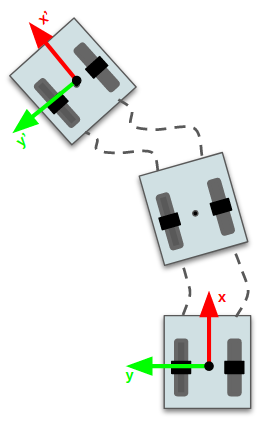

Figure 1: A differential-drive robot moving in a plane. The inertial reference frame (x and y axes) coincides with the robot reference frame (x’ and y’) at the starting point. The pose of the mobile robot after a displacement is expressed relative to the inertial reference frame.

### Orientation and Angular Velocity

The orientation of the robot reference frame (in radians) relative to the inertial reference frame is given by equation 1.2:

$$\theta = \frac{D_G - D_D}{l}$$

The rotational velocity in radians/sec (equation 1.3):

$$\omega = \frac{D_G - D_D}{l \cdot t}$$

In terms of the linear velocities of each wheel (equation 1.4):

$$\omega = \frac{v_G - v_D}{l}$$

where $v_G$ and $v_D$ are the velocities of the left and right wheels, respectively, in m/sec.

### Linear Velocity of the Robot

The linear velocity of the reference frame associated with the mobile robot is simply the average of the velocities of the two wheels (equation 1.5):

$$v = \frac{v_G + v_D}{2}$$

### Integral Kinematic Equations

Once we know the expressions for $v$ and $\omega$, we simply need to solve the following integrals to quantify the translational and rotational displacement:

$$\Delta x = \int_0^t v(t) \cos(\theta(t)) dt \quad \text{(1.6)}$$

$$\Delta y = \int_0^t v(t) \sin(\theta(t)) dt \quad \text{(1.7)}$$

$$\Delta \theta = \int_0^t \omega(t) dt \quad \text{(1.8)}$$

## 1.3.3 Discrete Implementation on the Robot

### Discretization of the Kinematic Equations

Equations 1.6 to 1.8 contain integrals that will be evaluated over a finite time horizon and repeatedly. Therefore, it is necessary to discretize these integrals so that they can be implemented in the Python node.

We will use the **Forward Euler Method** to approximate the integrals.

By discretizing equations 1.6 to 1.8, we obtain the following equations:

$$x_{k+1} = x_k + v_k \cdot T_s \cdot \cos(\theta_k) \quad \text{(1.9)}$$

$$y_{k+1} = y_k + v_k \cdot T_s \cdot \sin(\theta_k) \quad \text{(1.10)}$$

$$\theta_{k+1} = \theta_k + \omega_k \cdot T_s \quad \text{(1.11)}$$

where:
- $k$ refers to an index identifying the time period ($k = 0, 1, 2, ...$)
- $T_s$ is the time period, in seconds, at which we will update the robot pose

### Discretized Velocities

The expressions for linear and angular velocity, in discrete form, are:

$$v_k = \frac{\Delta s}{T_s} \quad \text{(1.12)}$$

$$\omega_k = \frac{\Delta \theta}{T_s} \quad \text{(1.13)}$$

where $T_s = t_{k+1} - t_k$.

$\Delta s$ and $\Delta \theta$ are respectively the distance traveled (in meters) and the angle covered (in radians) by the robot during a given time period:

$$\Delta s = \frac{\Delta D_G + \Delta D_D}{2} \quad \text{(1.14)}$$

$$\Delta \theta = \frac{\Delta D_D - \Delta D_G}{l} \quad \text{(1.15)}$$

where $\Delta D_G$ and $\Delta D_D$ are respectively the distances traveled by the left and right wheels during a time period $T_s$.

### Distances as a Function of Encoder Counts

The distances traveled can be expressed as a function of the number of encoder pulses:

$$\Delta D_G = 2\pi r \frac{\Delta enc\_a}{enc\_tour} \quad \Delta D_D = 2\pi r \frac{\Delta enc\_b}{enc\_tour} \quad \text{(1.16)}$$

where:
- $\Delta enc\_a = (enc\_a_{k+1} - enc\_a_k)$: number of encoder pulses for the left wheel
- $\Delta enc\_b = (enc\_b_{k+1} - enc\_b_k)$: number of encoder pulses for the right wheel
- $enc\_tour$: total number of pulses for one complete rotation of the wheel
- $r$: wheel radius

### Robot Kinematic Parameters

The following table presents the kinematic parameters of the mobile robots used in the course:

| Element | Parameter | Value |
|---------|-----------|--------|
| Wheels | radius (r) | 3.575 cm |
| Wheels | distance l | 16.55 cm |
| Encoders | enc_tour | 632.8 pulses/revolution |
| Encoder A | associated wheel | left |
| Encoder B | associated wheel | right |
| Encoder A | polarity | decrements when the robot moves forward |
| Encoder B | polarity | increments when the robot moves forward |

### Simplification for Implementation

Equations 1.9 to 1.11 can be **simplified** by substituting equations 1.12 and 1.13:

Since $v_k \cdot T_s = \Delta s$ and $\omega_k \cdot T_s = \Delta \theta$, we obtain directly:

$$x_{k+1} = x_k + \Delta s \cdot \cos(\theta_k)$$

$$y_{k+1} = y_k + \Delta s \cdot \sin(\theta_k)$$

$$\theta_{k+1} = \theta_k + \Delta \theta$$

This avoids explicitly calculating the velocities $v_k$ and $\omega_k$ in the code, since we already know $\Delta s$ and $\Delta \theta$ from the encoders.

## 1.3.4 System Architecture

Before implementing the code, it is important to understand the overall architecture of the system:

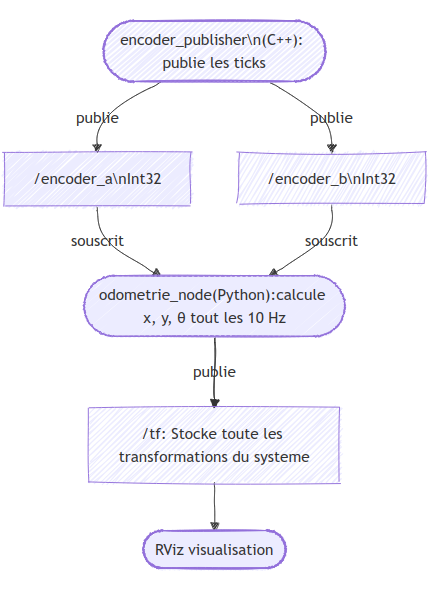

### ROS Topics Used

- **`/encoder_a`** (`std_msgs/Int32`): Absolute value of the left wheel encoder (published by `encoder_publisher`)
- **`/encoder_b`** (`std_msgs/Int32`): Absolute value of the right wheel encoder (published by `encoder_publisher`)
- **`/tf`**: Spatial transformations (`odom` → `base_link`) - published by our odometry node

## 1.3.5 TF: The ROS2 Coordinate Frame System

TF (Transform) is a fundamental ROS2 tool that manages spatial relationships between the different parts of a robot and its environment.

### What is TF?

Imagine a mobile robot with a camera mounted on top. For the robot to understand what it sees, it needs to know where the camera is relative to its wheels, where its wheels are relative to the ground, and so on. TF precisely manages these position and orientation relationships in 3D space.

### How does it work?

TF creates a coordinate tree where each part of the robot (and the objects around it) has its own reference frame called a "frame". For example:

- `base_link`: the center of the robot
- `camera_link`: the position of the camera
- `wheel_left`: the left wheel
- `map`: the map of the environment

TF maintains the transformations (position + rotation) between all these frames in real time, even when the robot moves.

### Why is it useful?

With TF, we can easily:
- Convert the coordinates of an object detected by the camera to the robot reference frame
- Determine where the robot is on a map
- Coordinate the movements of different parts of the robot

Instead of manually calculating all these geometric conversions, TF does it automatically for us, which greatly simplifies robotics development. This is the tool that will allow us to update the robot's position in space.

### Using the `tf2` Library

These explanations are taken from the [ROS2 documentation](https://docs.ros.org/en/humble/Tutorials/Intermediate/Tf2/Tf2-Main.html) on TF.

#### Publishing a Transformation
In the case of publishing or updating a TF, the user initializes an object of type `TransformBroadcaster`. Example:
```python
# In the class __init__
self.br = TransformBroadcaster(self)
```
Once the new position has been calculated, the transformation can be published. Example:
```python
self.br.sendTransform(self.robot_pose)
```
Using the `self.robot_pose` variable of type [`geometry_msgs/TransformStamped`](https://docs.ros.org/en/noetic/api/geometry_msgs/html/msg/TransformStamped.html). Looking carefully at this message, we can see three interesting fields:
```python
# This variable corresponds to the origin of the transformation. Here, the odom frame
self.robot_pose.header.frame_id = 'odom'

# This variable corresponds to the target frame of the transformation
self.robot_pose.child_frame_id = 'base_link'

# The translation or orientation variable corresponds to the transformation values
self.robot_pose.transform.translation.x = 0.0
self.robot_pose.transform.rotation.x = 0.0
```

#### Reading a Transformation
To read a transformation, ROS provides a `buffer` (a storage variable) that allows all transformations published during the last 5 seconds to be stored.
```python
# In the class __init__
self.tf_buffer = Buffer()
self.tf_listener = TransformListener(self.tf_buffer, self)
```
When the user needs the transformation between two reference frames, they can use the `lookup_transform` function:
```python
# Always call this function inside a try-except so that the node does not crash.
try:
    # The function has three arguments
    transform = self.tf_buffer.lookup_transform(
        to_frame_rel,    # The source frame
        from_frame_rel,  # The target frame
        rclpy.time.Time())  # The exact time to consider
except TransformException as ex:
    self.get_logger().info(
        f'Could not transform {to_frame_rel} to {from_frame_rel}: {ex}')
```
The `transform` variable is of type `geometry_msgs/TransformStamped`.

**Note**: For this laboratory, we will only use the **broadcaster** (TF publication), not the listener.

## 1.3.6 Using the `jerro_description` Package

During the previous laboratory, we downloaded the `jerro_description` package. This package describes the structure of the robot and publishes the position of each of its components relative to one another in ROS 2.

It is mainly composed of two elements:

* `urdf/jerro.urdf`
* `launch/jerro_description.launch.py`

These files work together to provide ROS with a consistent representation of the robot and its state. In this laboratory, we will use the launch file, but we will see how to create one in Laboratory 2b.

### Unified Robot Description File (URDF)

A URDF (Unified Robot Description File) is an XML file used by ROS to describe a robot in a structured way.

It allows you to define:

* the robot's links: rigid parts such as the chassis, wheels, arms, sensors, etc.
* the joints between these links: fixed, revolute, prismatic, etc.
* the geometry of the elements (for visualization and sometimes collision)
* physical properties (mass, inertia)
* the coordinate frames associated with each component

Using this file, tools such as RViz can correctly display the robot in 3D and understand how its different parts are connected.

### Publishing Transformations (TF)

For ROS to know where each part of the robot is at any given time, it is necessary to publish the transformations between the different coordinate frames. These transformations are broadcast through the ROS TF (Transform Frames) system.

In the `jerro_description.launch.py` launch file, two main nodes are launched:

* `robot_state_publisher`
* `joint_state_publisher`

#### `joint_state_publisher`

The `joint_state_publisher` node is responsible for providing the values of the robot's joints (angles, linear positions, etc.).

Specifically, it publishes a `JointState` message on the `/joint_states` topic. This message contains the current position of each joint. These values can be fixed, controlled through a graphical interface, or through the `/set_joint_states` topic with a message of type [`sensor_msgs/JointState`](https://docs.ros.org/en/noetic/api/sensor_msgs/html/msg/JointState.html).

#### `robot_state_publisher`

The `robot_state_publisher` node uses:

* the robot model (URDF)
* the joint values published by `joint_state_publisher`

to automatically calculate and publish TF transformations between all the robot's links and the position of each component in the transformation tree.

In other words, it transforms a static description (URDF) and joint states into a dynamic and consistent representation of the robot in ROS.

## 1.3.7 Implementation of the Odometry Node

### Package Creation

To implement the odometry functionality of **Jerro**, we will create the `jerro_odometrie` package.
This package will be developed in **Python** and will require the following dependencies: `rclpy`, `std_msgs`, `geometry_msgs`, `sensor_msgs`, `tf2_ros`, and `jerro_msgs`.

**Command to run in the terminal**:

```bash
cd ~/ros2_ws/src
ros2 pkg create jerro_odometrie --build-type ament_python \
  --dependencies rclpy std_msgs geometry_msgs sensor_msgs tf2_ros jerro_msgs
```

This command will create:
- The `jerro_odometrie/jerro_odometrie/` directory where you will put your Python files
- The `package.xml` file with the dependencies
- The `setup.py` file that we will modify

Once the package has been created, you can add the Python node file named `odometrie.py` to the `jerro_odometrie/jerro_odometrie/` directory.

### Configuring the setup.py File

For ROS2 to find and execute your node, you need to modify the `setup.py` file:

Open the `jerro_odometrie/setup.py` file and modify the `entry_points` section:

```python
entry_points={
    'console_scripts': [
        'odometrie = jerro_odometrie.odometrie:main',
    ],
},
```

This allows you to launch the node with the command:
```bash
ros2 run jerro_odometrie odometrie
```

⚠️ **Without this modification, you will get the error**: `executable 'odometrie' not found`

### Implementation Algorithm

Before coding, make sure you understand the sequence of operations:

```
INITIALIZATION (in __init__):
  1. Define the robot's physical parameters (r, l, enc_tour)
  2. Initialize the state variables (x=0, y=0, theta=0)
  3. Initialize the encoder variables (current and previous)
  4. Create the TF broadcaster
  5. Create subscribers for /encoder_a and /encoder_b
  6. Create the timer at 10 Hz

ON EACH ENCODER RECEPTION (callbacks):
  1. Store the new value in enc_a_current or enc_b_current
  2. If this is the first reception → also initialize enc_x_previous

ON EACH TIMER TICK (10 Hz):
  1. Calculate Δenc_a and Δenc_b (current - previous)

  2. Calculate ΔD_G and ΔD_D using equation 1.16:
     ΔD = 2πr × Δenc / enc_tour

  3. Calculate Δs and Δθ using equations 1.14 and 1.15:
     Δs = (ΔD_G + ΔD_D) / 2
     Δθ = (ΔD_D - ΔD_G) / l

  4. Update the position (simplified equations):
     x = x + Δs × cos(θ)
     y = y + Δs × sin(θ)
     θ = θ + Δθ

  5. Normalize θ between -π and π

  6. Convert θ to a quaternion (using scipy)

  7. Publish the TF transformation (odom → base_link)

  8. Save current encoder values → previous encoder values for the next iteration
```

### Quaternions

ROS, like many robotics frameworks, uses **quaternions** to represent rotations.
**TF** messages require this format.

When calculating the robot's position, it is necessary to convert **Euler angles** into quaternions. Fortunately, a Python library makes this conversion simple:

```python
# Import the library
from scipy.spatial.transform import Rotation as R
```

**Note**: scipy is already installed on the Raspberry Pi units. If you are working on your personal computer, install it with:
```bash
pip3 install scipy
```

### Building the Package

Once your code is written, you need to build the workspace:

```bash
cd ~/ros2_ws
colcon build --packages-select jerro_odometrie
source install/setup.bash
```

If the build succeeds, you can launch your node with:
```bash
ros2 run jerro_odometrie odometrie
```

## 1.3.8 Validation and Testing

### Checks Before Starting

Before launching your odometry node, verify that the encoder topics exist:

```bash
# First launch the motor control system
ros2 launch jerro_drivers motor_control.launch.py

# In another terminal, check the topics
ros2 topic list | grep encoder
```

You should see:
```
/encoder_a
/encoder_b
```

You can also view the values in real time:
```bash
ros2 topic echo /encoder_a
```

### Test Procedure

To verify that your **localization / odometry** node is working correctly, follow the steps below:

1. **Place the robot on the floor**, aligned with a straight line, in order to verify that the calculated distance corresponds to the actual distance traveled.

2. **Launch the nodes** in the following order (each in a separate terminal):

   **Terminal 1** - Motor control system:
   ```bash
   cd ~/ros2_ws
   source install/setup.bash
   ros2 launch jerro_drivers motor_control.launch.py
   ```

   **Terminal 2** - Your odometry node:
   ```bash
   cd ~/ros2_ws
   source install/setup.bash
   ros2 run jerro_odometrie odometrie
   ```

   **Terminal 3** - Your `navigation` package node if you have one from previous labs:
   ```bash
   cd ~/ros2_ws
   source install/setup.bash
   ros2 run jerro_navigation <node_name>
   ```

   **Terminal 4** - Teleoperation:
   ```bash
   cd ~/ros2_ws
   source install/setup.bash
   ros2 run teleop_twist_keyboard teleop_twist_keyboard
   ```
   **Terminal 5** - TF description:
   ```bash
   cd ~/ros2_ws
   source install/setup.bash
   ros2 launch jerro_description jerro_description.launch.py
   ```
3. **Control the robot** using the `teleop_keyboard` user interface.
   It is recommended to remove the `print` outputs for wheel speed to make it easier to read the messages published by your odometry node.

4. **Check the pose information** obtained (position and orientation) and compare it with a manual measurement made using a measuring tape.
   As a reminder, **one floor tile corresponds to 30 cm**.

### Simple Test Example

1. Note the robot's initial position on a line
2. Move the robot forward by 2 tiles (60 cm) in a straight line
3. Look at the logs from your odometry node
4. The value of `x` should be close to 0.6 m
5. The values of `y` and `θ` should remain close to 0

### Visualization with Rviz
```bash
ros2 run rviz2 rviz2
```
You should now see:
- A grid representing the plane
- The axes of the `odom` frame (red, green, blue)
- The axes of the `base_link` frame moving with the robot

### Debugging (FAQ)

#### Problem: "Executable 'odometrie' not found"
**Solution**: Make sure you modified the `setup.py` file with the entry point, then rebuild:
```bash
cd ~/ros2_ws
colcon build --packages-select jerro_odometrie
source install/setup.bash
```

#### Problem: My node does not publish anything / Position remains at (0, 0, 0)
**Possible solutions**:
1. Check that `motor_control.launch.py` is running (the encoders must be publishing)
2. Check the topic names: `/encoder_a` and `/encoder_b` (with the slash)
3. Check that `_encodeurs_initialises` becomes `True` in the callbacks
4. Add logs for debugging:
   ```python
   self.get_logger().info(f'enc_a received: {msg.data}')
   ```

#### Problem: ImportError: cannot import name 'TransformBroadcaster'
**Solution**: Check your imports; they should be:
```python
from tf2_ros import TransformBroadcaster
```
Also check that `tf2_ros` is included in the `package.xml` dependencies.

#### Problem: ModuleNotFoundError: No module named 'scipy'
**Solution**: Install scipy:
```bash
pip3 install scipy
```

## 1.3.9 Demonstration to the Laboratory Instructor

For this laboratory, you simply need to validate the operation of your localization algorithm with the laboratory instructor.

**What will be evaluated**:
1. Your node builds and launches without errors
2. The TF transformation (odom → base_link) is published
3. The robot moves and its position is updated in Rviz
4. The calculated distance is consistent with the actual distance (within ±10%)

## Additional Notes

### Object-Oriented Programming in Python

Useful resources:

- [Official Python 3 documentation](https://docs.python.org/3/tutorial/classes.html)
- [W3Schools Python Classes](https://www.w3schools.com/python/python_classes.asp)

### Programming Conventions

- Attributes preceded by an underscore (_) are conventionally reserved for internal use within the class
- The `self.` prefix is used to access class attributes and methods from within the class
- Variables created with `self.` in the constructor (`__init__`) are instance variables (accessible throughout the class)

### ROS Frames

- **odom**: Fixed odometry frame, with its origin at the robot's starting point
- **base_link**: Mobile frame attached to the robot, with its origin located halfway between the wheels, on the ground